In [8]:
!pip install seaborn

from pathlib import Path
from urllib.request import urlretrieve
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

 
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
pd.set_option("display.float_format", "{:,.2f}".format) 

print("Biblioteki są gotowe.")


Biblioteki są gotowe.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from pathlib import Path

current_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in (current_dir, *current_dir.parents)
        if (path / "src" / "data_loader.py").is_file()
        and (path / "data" / "raw").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Check the project structure "
        "and the location of src/data_loader.py."
    )

DATA_DIR = PROJECT_ROOT / "data" / "raw"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data directory: {DATA_DIR}")
print(f"Directory exists: {DATA_DIR.exists()}")
print(f"Files: {[file.name for file in DATA_DIR.iterdir()]}")


Project root: C:\Users\Nastya\Documents\retail-sales-forecasting
Raw data directory: C:\Users\Nastya\Documents\retail-sales-forecasting\data\raw
Directory exists: True
Files: ['.ipynb_checkpoints', 'store.csv', 'train.csv']


In [10]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data

df = load_data()

display(df.head())
print(f"Shape: {df.shape}")

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,CompetitionDistanceMissing,CompetitionInfoMissing
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,"1,270.00",9.00,"2,008.00",0,NaN,NaN,NaN,0,0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct",0,0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct",0,0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,"2,009.00",0,NaN,NaN,NaN,0,0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,"29,910.00",4.00,"2,015.00",0,NaN,NaN,NaN,0,0


Shape: (1017209, 20)


In [11]:
import pandas as pd

train = pd.read_csv(
    DATA_DIR / "train.csv",
    parse_dates=["Date"],
    dtype={"StateHoliday": "string"},
)

stores = pd.read_csv(DATA_DIR / "store.csv")

display(train.head())
display(stores.head())

print("\nColumns train:")
print(train.columns.tolist())

print("\nColumns store:")
print(stores.columns.tolist())

print(f"\nTrain shape: {train.shape}")
print(f"Stores shape: {stores.shape}")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.00",9.00,"2,008.00",0,NaN,NaN,NaN
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,"2,009.00",0,NaN,NaN,NaN
4,5,a,a,"29,910.00",4.00,"2,015.00",0,NaN,NaN,NaN



Columns train:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Columns store:
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

Train shape: (1017209, 9)
Stores shape: (1115, 10)


In [12]:
display(train.head())
display(stores.head())

print("\nColumns train:")
print(train.columns.tolist())

print("\nColumns store:")
print(stores.columns.tolist())

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.00",9.00,"2,008.00",0,NaN,NaN,NaN
1,2,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,c,c,620.00,9.00,"2,009.00",0,NaN,NaN,NaN
4,5,a,a,"29,910.00",4.00,"2,015.00",0,NaN,NaN,NaN



Columns train:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

Columns store:
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


In [ ]:
analysis_df = train

sales_row_count = len(analysis_df)
sales_column_count = len(analysis_df.columns)
sales_columns = list(analysis_df.columns)
sales_dtype = analysis_df.dtypes
sales_missing_values = analysis_df.isna().sum()

numeric_summary = analysis_df.select_dtypes(include="number").describe()
categorical_summary = analysis_df.select_dtypes(
    include=["object", "bool", "category"]
).describe()

analysis_df["StateHoliday"].value_counts(dropna=False)

print("-" * 50)

print("\nLiczba wierszy w analysis_df:", sales_row_count)

print("\nLiczba kolumn w analysis_df:", sales_column_count)

print("\nLista nazw kolumn analysis_df:", sales_columns)

print("\nTypy danych w analysis_df:\n", sales_dtype)

print("\nLiczba braków w każdej kolumnie analysis_df:\n",
      sales_missing_values)

print("\nOpis kolumn liczbowych analysis_df:\n",
      numeric_summary)

print("\nOpis kolumn tekstowych i logicznych analysis_df:\n",
      categorical_summary)

print("-" * 50)

Wnioski z wstępnej analizy danych

Zbiór danych zawiera 1 017 209 obserwacji i nie wykazuje brakujących wartości w analizowanych kolumnach. Zmienna Sales charakteryzuje się dużym zakresem wartości, od 0 do 41 551, co wskazuje na potrzebę dalszej analizy rozkładu sprzedaży i potencjalnych wartości odstających. Około 83% obserwacji dotyczy otwartych sklepów, a promocje występują w około 38% przypadków. Zmienna StateHoliday ma pięć unikalnych wartości, przy czym najczęściej występuje wartość 0. Przed budową modeli należy zweryfikować duplikaty, rozkład sprzedaży, zależności między zmiennymi oraz strukturę szeregu czasowego. W przypadku prognozowania sprzedaży na kolejne 30 dni należy również wykluczyć wykorzystanie informacji, które nie będą dostępne w momencie prognozy.

In [23]:
analysis_df = stores

store_row_count = len(analysis_df)
store_column_count = len(analysis_df.columns)
store_columns = list(analysis_df.columns)
store_dtype = analysis_df.dtypes
store_missing_values = analysis_df.isna().sum()

numeric_summary = analysis_df.select_dtypes(include="number").describe()
categorical_summary = analysis_df.select_dtypes(
    include=["object", "str", "bool", "category"]
).describe()

print("-" * 50)

print("\nLiczba wierszy w stores:", store_row_count)

print("\nLiczba kolumn w stores:", store_column_count)

print("\nLista nazw kolumn stores:", store_columns)

print("\nTypy danych w stores:\n", store_dtype)

print("\nLiczba braków w każdej kolumnie stores:\n",
      store_missing_values)

print("\nOpis kolumn liczbowych stores:\n",
      numeric_summary)

print("\nOpis kolumn tekstowych i logicznych stores:\n",
      categorical_summary)

print("-" * 50)

--------------------------------------------------

Liczba wierszy w stores: 1115

Liczba kolumn w stores: 10

Lista nazw kolumn stores: ['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

Typy danych w stores:
 Store                          int64
StoreType                        str
Assortment                       str
CompetitionDistance          float64
CompetitionOpenSinceMonth    float64
CompetitionOpenSinceYear     float64
Promo2                         int64
Promo2SinceWeek              float64
Promo2SinceYear              float64
PromoInterval                    str
dtype: object

Liczba braków w każdej kolumnie stores:
 Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0


### Wnioski z analizy zbioru `stores`

Zbiór `stores` zawiera informacje o 1 115 sklepach, w tym o ich typie, asortymencie, odległości od konkurencji oraz udziale w promocjach. W kolumnie `CompetitionDistance` występują tylko 3 brakujące wartości, natomiast w kolumnach `CompetitionOpenSinceMonth` i `CompetitionOpenSinceYear` brakuje danych dla około 31,7% sklepów. Zmienna `CompetitionDistance` charakteryzuje się dużym zróżnicowaniem wartości — mediana wynosi 2 325, a maksimum 75 860. W zbiorze występują 4 typy sklepów i 3 kategorie asortymentu. Około 51% sklepów uczestniczy w długoterminowych promocjach (`Promo2`). Przed modelowaniem należy odpowiednio obsłużyć braki danych, sprawdzić rozkład odległości od konkurencji oraz połączyć zbiór `stores` ze zbiorem `train` na podstawie kolumny `Store`.


In [23]:
def data_quality_report(df, name):
    report = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": df.isna().mean().mul(100).round(2),
        "unique_values": df.nunique(dropna=True),
    })

    print(f"\n=== {name}: Jakość danych ===")
    print(f"Wierszy: {len(df):,}")
    print(f"Kolumny: {df.shape[1]}")
    print(f"Duplikaty: {df.duplicated().sum():,}")

    display(report.sort_values("missing_pct", ascending=False))

    return report


train_quality = data_quality_report(train, "TRAIN")
store_quality = data_quality_report(stores, "STORES")


=== TRAIN: Jakość danych ===
Wierszy: 1,017,209
Kolumny: 9
Duplikaty: 0


,dtype,missing_count,missing_pct,unique_values
Store,int64,0,0.00,1115
DayOfWeek,int64,0,0.00,7
Date,datetime64[us],0,0.00,942
Sales,int64,0,0.00,21734
Customers,int64,0,0.00,4086
Open,int64,0,0.00,2
Promo,int64,0,0.00,2
StateHoliday,object,0,0.00,5
SchoolHoliday,int64,0,0.00,2



=== STORES: Jakość danych ===
Wierszy: 1,115
Kolumny: 10
Duplikaty: 0


,dtype,missing_count,missing_pct,unique_values
PromoInterval,str,544,48.79,3
Promo2SinceYear,float64,544,48.79,7
Promo2SinceWeek,float64,544,48.79,24
CompetitionOpenSinceYear,float64,354,31.75,23
CompetitionOpenSinceMonth,float64,354,31.75,12
CompetitionDistance,float64,3,0.27,654
StoreType,str,0,0.00,4
Store,int64,0,0.00,1115
Assortment,str,0,0.00,3
Promo2,int64,0,0.00,2


In [25]:

# 1. Zakres dat i liczba sklepów

print("=== Zakres dat sprzedaży ===")
print("Data początkowa:", train["Date"].min())
print("Data końcowa:", train["Date"].max())

print("\n=== Liczba sklepów ===")
print("Liczba unikalnych sklepów w zbiorze train:",
      train["Store"].nunique())
print("Liczba unikalnych sklepów w zbiorze stores:",
      stores["Store"].nunique())


# 2. Sprawdzenie duplikatów

# Każdy sklep powinien mieć maksymalnie jeden rekord dla danego dnia.
print("\n=== Duplikaty w zbiorze train ===")
print("Liczba duplikatów dla kombinacji Store + Date:",
      train.duplicated(subset=["Store", "Date"]).sum())

# Każdy sklep powinien występować tylko raz w zbiorze stores.
print("\n=== Duplikaty w zbiorze stores ===")
print("Liczba duplikatów w kolumnie Store:",
      stores.duplicated(subset=["Store"]).sum())


# 3. Statystyki opisowe sprzedaży

print("\n=== Statystyki opisowe sprzedaży ===")
display(train["Sales"].describe())


# 4. Kontrola wartości sprzedaży

print("\n=== Kontrola wartości sprzedaży ===")
print("Liczba dni z zerową sprzedażą:",
      (train["Sales"] == 0).sum())

print("Liczba obserwacji z ujemną sprzedażą:",
      (train["Sales"] < 0).sum())


# 5. Sprawdzenie statusu otwarcia sklepów

print("\n=== Status otwarcia sklepów ===")
print("Liczba obserwacji według statusu Open:")
display(train["Open"].value_counts(dropna=False))


# 6. Sprawdzenie dni tygodnia

print("\n=== Wartości w kolumnie DayOfWeek ===")
print("Unikalne dni tygodnia:",
      sorted(train["DayOfWeek"].dropna().unique()))


=== Zakres dat sprzedaży ===
Data początkowa: 2013-01-01 00:00:00
Data końcowa: 2015-07-31 00:00:00

=== Liczba sklepów ===
Liczba unikalnych sklepów w zbiorze train: 1115
Liczba unikalnych sklepów w zbiorze stores: 1115

=== Duplikaty w zbiorze train ===
Liczba duplikatów dla kombinacji Store + Date: 0

=== Duplikaty w zbiorze stores ===
Liczba duplikatów w kolumnie Store: 0

=== Statystyki opisowe sprzedaży ===


count   1,017,209.00
mean        5,773.82
std         3,849.93
min             0.00
25%         3,727.00
50%         5,744.00
75%         7,856.00
max        41,551.00
Name: Sales, dtype: float64


=== Kontrola wartości sprzedaży ===
Liczba dni z zerową sprzedażą: 172871
Liczba obserwacji z ujemną sprzedażą: 0

=== Status otwarcia sklepów ===
Liczba obserwacji według statusu Open:


Open
1    844392
0    172817
Name: count, dtype: int64


=== Wartości w kolumnie DayOfWeek ===
Unikalne dni tygodnia: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


In [32]:

# Analiza brakujących danych w kolumnach związanych z promocjami

promo_columns = [
    "Promo2SinceWeek",
    "Promo2SinceYear",
    "PromoInterval"
]

print("=== Braki danych według wartości Promo2 ===")

for col in promo_columns:
    print(f"\nKolumna: {col}")
    display(pd.crosstab(
        stores["Promo2"],
        stores[col].isna(),
        rownames=["Promo2"],
        colnames=["Czy brakuje danych?"],
        margins=True
    ))

# Sprawdzenie, czy sklepy bez Promo2 mają braki w tych kolumnach
print("\nLiczba sklepów z Promo2 = 0:",
      (stores["Promo2"] == 0).sum())

print("Liczba sklepów z Promo2 = 1:",
      (stores["Promo2"] == 1).sum())


=== Braki danych według wartości Promo2 ===

Kolumna: Promo2SinceWeek


Czy brakuje danych?,False,True,All
Promo2,,,
0,0,544,544
1,571,0,571
All,571,544,1115



Kolumna: Promo2SinceYear


Czy brakuje danych?,False,True,All
Promo2,,,
0,0,544,544
1,571,0,571
All,571,544,1115



Kolumna: PromoInterval


Czy brakuje danych?,False,True,All
Promo2,,,
0,0,544,544
1,571,0,571
All,571,544,1115



Liczba sklepów z Promo2 = 0: 544
Liczba sklepów z Promo2 = 1: 571


In [26]:

# 1. Porównanie sprzedaży w zależności od statusu sklepu

print("=== Sprzedaż w zależności od statusu sklepu ===")

sales_by_open = train.groupby("Open")["Sales"].agg(
    ["count", "mean", "median", "min", "max", "sum"]
)

sales_by_open = sales_by_open.rename(
    index={0: "Sklep zamknięty", 1: "Sklep otwarty"}
)

display(sales_by_open)


=== Sprzedaż w zależności od statusu sklepu ===


,count,mean,median,min,max,sum
Open,,,,,,
Sklep zamknięty,172817,0.00,0.00,0,0,0
Sklep otwarty,844392,"6,955.51","6,369.00",0,41551,5873180623


In [27]:

# 2. Tabela zależności między statusem sklepu a sprzedażą

sales_open_table = pd.crosstab(
    train["Open"],
    train["Sales"] > 0,
    rownames=["Status sklepu (Open)"],
    colnames=["Czy wystąpiła sprzedaż?"]
)

sales_open_table = sales_open_table.rename(
    index={0: "Zamknięty", 1: "Otwarty"},
    columns={False: "Nie", True: "Tak"}
)

display(sales_open_table)


Czy wystąpiła sprzedaż?,Nie,Tak
Status sklepu (Open),,
Zamknięty,172817,0
Otwarty,54,844338


In [28]:

# 3. Wyszukanie przypadków sprzedaży w zamkniętych sklepach

closed_with_sales = train[
    (train["Open"] == 0) &
    (train["Sales"] > 0)
]

print("=== Sprzedaż w zamkniętych sklepach ===")

print("Liczba przypadków, w których sklep był zamknięty, "
      "ale odnotowano dodatnią sprzedaż:",
      len(closed_with_sales))

# Wyświetlenie przykładowych rekordów
display(closed_with_sales.head(10))

# Podstawowe statystyki sprzedaży w tych przypadkach
if not closed_with_sales.empty:
    print("\nStatystyki sprzedaży w zamkniętych sklepach:")
    display(closed_with_sales["Sales"].describe())

    # Sprawdzenie, których sklepów i dat dotyczą te obserwacje
    print("\nNumery sklepów i daty:")
    display(
        closed_with_sales[
            ["Store", "Date", "DayOfWeek", "Sales", "Customers", "Open"]
        ].sort_values(["Store", "Date"])
    )
else:
    print("Nie znaleziono przypadków sprzedaży w zamkniętych sklepach.")


=== Sprzedaż w zamkniętych sklepach ===
Liczba przypadków, w których sklep był zamknięty, ale odnotowano dodatnią sprzedaż: 0


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday


Nie znaleziono przypadków sprzedaży w zamkniętych sklepach.


**Analiza brakujących okresów w oryginalnym zbiorze train**
***przed połączeniem tabel train i stores***


In [25]:


train["Date"] = pd.to_datetime(train["Date"])

# Ustalenie pełnego zakresu dat w zbiorze train
START_DATE = train["Date"].min()
END_DATE = train["Date"].max()

expected_dates = pd.date_range(
    start=START_DATE,
    end=END_DATE,
    freq="D",
)

print("Początek okresu:", START_DATE)
print("Koniec okresu:", END_DATE)
print("Liczba dni kalendarzowych:", len(expected_dates))

missing_periods_list = []

# Analiza brakujących dat dla każdego sklepu
for store_id, group in train.groupby("Store"):
    observed_dates = pd.DatetimeIndex(group["Date"].unique())
    missing_dates = expected_dates.difference(observed_dates)

    if len(missing_dates) == 0:
        continue

    # Podział brakujących dat na ciągłe okresy
    missing_series = pd.Series(missing_dates).sort_values().reset_index(drop=True)
    group_id = missing_series.diff().dt.days.ne(1).cumsum()

    periods = (
        pd.DataFrame({
            "Date": missing_series,
            "Group": group_id,
        })
        .groupby("Group")["Date"]
        .agg(["min", "max", "count"])
        .reset_index(drop=True)
        .rename(columns={
            "min": "Data_od",
            "max": "Data_do",
            "count": "Liczba_dni",
        })
    )

    periods.insert(0, "Store", store_id)
    missing_periods_list.append(periods)

# Utworzenie tabeli wszystkich brakujących okresów
if missing_periods_list:
    missing_periods = (
        pd.concat(missing_periods_list, ignore_index=True)
        .sort_values(["Store", "Data_od"])
        .reset_index(drop=True)
    )
else:
    missing_periods = pd.DataFrame(
        columns=["Store", "Data_od", "Data_do", "Liczba_dni"]
    )

print("Liczba sklepów z brakującymi okresami:",
      missing_periods["Store"].nunique())

print("Liczba brakujących okresów:",
      len(missing_periods))

display(missing_periods)

Początek okresu: 2013-01-01 00:00:00
Koniec okresu: 2015-07-31 00:00:00
Liczba dni kalendarzowych: 942
Liczba sklepów z brakującymi okresami: 181
Liczba brakujących okresów: 181


,Store,Data_od,Data_do,Liczba_dni
0,13,2014-07-01,2014-12-31,184
1,20,2014-07-01,2014-12-31,184
2,22,2014-07-01,2014-12-31,184
3,32,2014-07-01,2014-12-31,184
4,36,2014-07-01,2014-12-31,184
...,...,...,...,...
176,1094,2014-07-01,2014-12-31,184
177,1102,2014-07-01,2014-12-31,184
178,1104,2014-07-01,2014-12-31,184
179,1107,2014-07-01,2014-12-31,184


In [26]:
# Podsumowanie brakujących okresów według sklepów
stores_missing_summary = (
    missing_periods.groupby("Store")
    .agg(
        Liczba_okresow=("Liczba_dni", "size"),
        Liczba_brakujacych_dni=("Liczba_dni", "sum"),
        Najdluzszy_okres=("Liczba_dni", "max"),
        Pierwsza_brakujaca_data=("Data_od", "min"),
        Ostatnia_brakujaca_data=("Data_do", "max"),
    )
    .sort_values(
        ["Najdluzszy_okres", "Liczba_brakujacych_dni"],
        ascending=False,
    )
)

display(stores_missing_summary.head(30))

,Liczba_okresow,Liczba_brakujacych_dni,Najdluzszy_okres,Pierwsza_brakujaca_data,Ostatnia_brakujaca_data
Store,,,,,
13,1,184,184,2014-07-01,2014-12-31
20,1,184,184,2014-07-01,2014-12-31
22,1,184,184,2014-07-01,2014-12-31
32,1,184,184,2014-07-01,2014-12-31
36,1,184,184,2014-07-01,2014-12-31
41,1,184,184,2014-07-01,2014-12-31
46,1,184,184,2014-07-01,2014-12-31
51,1,184,184,2014-07-01,2014-12-31
52,1,184,184,2014-07-01,2014-12-31


**Wnioski**
Przed połączeniem tabel train i stores przeprowadzono analizę brakujących okresów w oryginalnym zbiorze train. Wykryto braki w danych dla 181 sklepów. Dla 180 z nich brakowało 184 kolejnych dni, od 1 lipca do 31 grudnia 2014 r. W pozostałym zakresie analizowanego okresu nie wykryto brakujących dat. 
Brakujące dane nie zostały uzupełnione zerami, ponieważ brak rekordu nie oznacza zerowej sprzedaży ani zamknięcia sklepu.
Zamiast tego zastosowano podział szeregów czasowych na ciągłe segmenty na podstawie różnic między kolejnymi datami.

Identyfikatory segmentów (segment_id) pozwalają obliczać opóźnienia sprzedaży (lag features) oraz statystyki kroczące (rolling mean) wyłącznie w obrębie tego samego segmentu. Dzięki temu wartości sprzed kilkumiesięcznej przerwy nie są wykorzystywane do wyznaczania cech dla obserwacji po przerwie. Dodatkowo statystyki kroczące są obliczane z przesunięciem o jedną obserwację (shift(1)), co zapobiega wykorzystaniu sprzedaży z bieżącego dnia.

Takie podejście pozwala zachować dostępne obserwacje i zapewnia spójne, powtarzalne tworzenie cech czasowych bez sztucznego uzupełniania brakujących danych.

In [33]:

# Przygotowanie zbioru stores do dalszej analizy

stores_clean = stores.copy()

# 1. Utworzenie wskaźników brakujących danych
# dotyczących konkurencji

competition_columns = [
    "CompetitionDistance",
    "CompetitionOpenSinceMonth",
    "CompetitionOpenSinceYear"
]

for col in competition_columns:
    stores_clean[f"{col}_Missing"] = (
        stores_clean[col].isna().astype("int8")
    )

# 2. Uzupełnienie brakujących odległości od konkurencji
# za pomocą mediany

competition_distance_median = (
    stores_clean["CompetitionDistance"].median()
)

stores_clean["CompetitionDistance"] = (
    stores_clean["CompetitionDistance"].fillna(
        competition_distance_median
    )
)

# 3. Pozostawienie braków w informacjach o promocjach
# oraz dacie otwarcia konkurencji na tym etapie

# 4. Kontrola wyników

print("=== Liczba braków po przetwarzaniu ===")
display(
    stores_clean.isna().sum()
    .sort_values(ascending=False)
    .to_frame(name="Liczba braków")
)

print("\nLiczba sklepów przed przetwarzaniem:", len(stores))
print("Liczba sklepów po przetwarzaniu:", len(stores_clean))


=== Liczba braków po przetwarzaniu ===


,Liczba braków
Promo2SinceYear,544
Promo2SinceWeek,544
PromoInterval,544
CompetitionOpenSinceYear,354
CompetitionOpenSinceMonth,354
CompetitionDistance,0
Assortment,0
StoreType,0
Store,0
Promo2,0



Liczba sklepów przed przetwarzaniem: 1115
Liczba sklepów po przetwarzaniu: 1115


In [34]:
# Sprawdzenie, czy wszystkie sklepy ze zbioru train
# znajdują się również w zbiorze stores

missing_store_ids = set(train["Store"]) - set(stores["Store"])

print("Liczba sklepów ze zbioru train, których brakuje w stores:",
      len(missing_store_ids))


Liczba sklepów ze zbioru train, których brakuje w stores: 0


In [53]:
# Połączenie zbiorów train i stores na podstawie kolumny Store
# validate="many_to_one" sprawdza, czy każdy sklep występuje
# maksymalnie raz w zbiorze stores

df = train.merge(
    stores_clean,
    on="Store",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("\nRozmiar połączonego zbioru danych:", df.shape)
print("\nWynik operacji łączenia zbiorów:")
print(df["_merge"].value_counts())

# Usunięcie kolumny pomocniczej informującej o wyniku łączenia
df = df.drop(columns="_merge")


# Przygotowanie kolumny Date do analizy szeregów czasowych

# Utworzenie kopii zbioru danych
df = df.copy()

# Konwersja kolumny Date na typ daty i czasu
df["Date"] = pd.to_datetime(df["Date"])


# Wybór obserwacji z dodatnią sprzedażą

sales_df = df.loc[
    df["Sales"].notna() & (df["Sales"] > 0)
].copy()

# Utworzenie zmiennej określającej rok i miesiąc
sales_df["YearMonth"] = (
    sales_df["Date"].dt.to_period("M").astype(str)
)

# Utworzenie zmiennej zawierającej nazwę dnia tygodnia
sales_df["DayOfWeekName"] = sales_df["Date"].dt.day_name()


# Podsumowanie liczby obserwacji

print("\n=== Podsumowanie zbioru danych ===")

print("Liczba wszystkich obserwacji:", len(df))

print("Liczba obserwacji z dodatnią sprzedażą:", len(sales_df))

print("Udział obserwacji z dodatnią sprzedażą:",
      f"{len(sales_df) / len(df):.1%}")



Rozmiar połączonego zbioru danych: (1017209, 22)

Wynik operacji łączenia zbiorów:
_merge
both          1017209
left_only           0
right_only          0
Name: count, dtype: int64

=== Podsumowanie zbioru danych ===
Liczba wszystkich obserwacji: 1017209
Liczba obserwacji z dodatnią sprzedażą: 844338
Udział obserwacji z dodatnią sprzedażą: 83.0%


In [55]:

# Wyszukanie dni, w których sklep był otwarty,
# ale nie odnotowano żadnej sprzedaży

zero_sales_open = df.loc[
    (df["Open"] == 1) &
    (df["Sales"] == 0)
].copy()

# Sortowanie według daty i numeru sklepu
zero_sales_open = zero_sales_open.sort_values(
    by=["Date", "Store"]
)

print("Liczba przypadków, w których sklep był otwarty, "
      "ale sprzedaż wynosiła 0:",
      len(zero_sales_open))

# Wyświetlenie najważniejszych kolumn
columns_to_show = [
    "Date", "Store", "DayOfWeek",
    "Open", "Sales", "Customers", "Promo", "StateHoliday", "SchoolHoliday"
]

display(zero_sales_open[columns_to_show])


Liczba przypadków, w których sklep był otwarty, ale sprzedaż wynosiła 0: 54


,Date,Store,DayOfWeek,Open,Sales,Customers,Promo,StateHoliday,SchoolHoliday
999016,2013-01-17,762,4,1,0,0,0,0,0
990681,2013-01-24,232,4,1,0,0,1,0,0
984098,2013-01-30,339,3,1,0,0,0,0,0
982983,2013-01-31,339,4,1,0,0,0,0,0
975098,2013-02-07,259,4,1,0,0,1,0,0
933937,2013-03-16,353,6,1,0,0,0,0,0
889932,2013-04-25,948,4,1,0,5,1,0,0
885113,2013-04-29,589,1,1,0,0,1,0,0
875968,2013-05-07,364,2,1,0,0,0,0,0
874853,2013-05-08,364,3,1,0,0,0,0,0


In [56]:

# Wyszukanie obserwacji z zerową sprzedażą,
# ale dodatnią liczbą klientów

zero_sales_with_customers = df.loc[
    (df["Sales"] == 0) &
    (df["Customers"] > 0)
].copy()

zero_sales_with_customers = zero_sales_with_customers.sort_values(
    by=["Date", "Store"]
)

print("Liczba przypadków z Sales = 0 i Customers > 0:",
      len(zero_sales_with_customers))

columns_to_show = [
    "Date", "Store", "DayOfWeek", "Open",
    "Sales", "Customers", "Promo",
    "StateHoliday", "SchoolHoliday"
]

display(zero_sales_with_customers[columns_to_show].head(50))


Liczba przypadków z Sales = 0 i Customers > 0: 2


,Date,Store,DayOfWeek,Open,Sales,Customers,Promo,StateHoliday,SchoolHoliday
889932,2013-04-25,948,4,1,0,5,1,0,0
478649,2014-04-29,1100,2,1,0,3,1,0,0


In [57]:

# Podsumowanie przypadków zerowej sprzedaży
# i dodatniej liczby klientów

print("Liczba przypadków:", len(zero_sales_with_customers))

if not zero_sales_with_customers.empty:
    print("\nRozkład liczby klientów:")
    display(
        zero_sales_with_customers["Customers"]
        .value_counts()
        .sort_index()
        .to_frame(name="Liczba obserwacji")
    )

    print("\nStatus otwarcia sklepu:")
    display(
        zero_sales_with_customers["Open"]
        .value_counts(dropna=False)
    )

    print("\nZakres dat:")
    print("Od:", zero_sales_with_customers["Date"].min())
    print("Do:", zero_sales_with_customers["Date"].max())
else:
    print("Nie znaleziono takich obserwacji.")


Liczba przypadków: 2

Rozkład liczby klientów:


,Liczba obserwacji
Customers,
3,1
5,1



Status otwarcia sklepu:


Open
1    2
Name: count, dtype: int64


Zakres dat:
Od: 2013-04-25 00:00:00
Do: 2014-04-29 00:00:00


### Analiza obserwacji z zerową sprzedażą i dodatnią liczbą klientów

W zbiorze danych zidentyfikowano 2 obserwacje, w których sklepy były oznaczone jako otwarte (`Open = 1`), liczba klientów była dodatnia (`Customers > 0`), natomiast sprzedaż wynosiła zero (`Sales = 0`). Przypadki te dotyczą sklepów 948 i 1100. Obserwacje te są nietypowe i mogą wynikać ze specyfiki rejestracji danych lub błędów ewidencyjnych. Na podstawie dostępnych informacji nie można jednoznacznie ustalić ich przyczyny. Przed modelowaniem należy zweryfikować te rekordy w oryginalnym zbiorze danych oraz przeanalizować sprzedaż w sąsiednich dniach. Nie zaleca się automatycznego usuwania tych obserwacji bez dodatkowej weryfikacji.

In [58]:
# Weryfikacja podejrzanych obserwacji w oryginalnym zbiorze train

suspicious_keys = [
    ("2013-04-25", 948),
    ("2014-04-29", 1100)
]

for date, store_id in suspicious_keys:
    record = train.loc[
        (pd.to_datetime(train["Date"]) == pd.Timestamp(date)) &
        (train["Store"] == store_id)
    ]

    print(f"\nData: {date}, sklep: {store_id}")
    display(record)


Data: 2013-04-25, sklep: 948


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
889932,948,4,2013-04-25,0,5,1,1,0,0



Data: 2014-04-29, sklep: 1100


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
478649,1100,2,2014-04-29,0,3,1,1,0,0


In [61]:
# Analiza sprzedaży w sąsiednich dniach

for date, store_id in suspicious_keys:
    date = pd.Timestamp(date)

    nearby = df.loc[
        (df["Store"] == store_id) &
        (df["Date"].between(
            date - pd.Timedelta(days=3),
            date + pd.Timedelta(days=3)
        ))
    ].sort_values("Date")

    print(f"\nSklep {store_id}, okolice daty {date.date()}")

    display(
        nearby[
            ["Date", "DayOfWeek", "Open", "Sales",
             "Customers", "Promo", "StateHoliday","SchoolHoliday"]
        ]
    )


Sklep 948, okolice daty 2013-04-25


,Date,DayOfWeek,Open,Sales,Customers,Promo,StateHoliday,SchoolHoliday
893277,2013-04-22,1,0,0,0,1,0,0
892162,2013-04-23,2,0,0,0,1,0,0
891047,2013-04-24,3,0,0,0,1,0,0
889932,2013-04-25,4,1,0,5,1,0,0
888817,2013-04-26,5,1,8520,1880,1,0,0
887702,2013-04-27,6,1,5340,1241,0,0,0
886587,2013-04-28,7,1,7404,1630,0,0,0



Sklep 1100, okolice daty 2014-04-29


,Date,DayOfWeek,Open,Sales,Customers,Promo,StateHoliday,SchoolHoliday
481994,2014-04-26,6,0,0,0,0,0,0
480879,2014-04-27,7,0,0,0,0,0,0
479764,2014-04-28,1,0,0,0,1,0,0
478649,2014-04-29,2,1,0,3,1,0,0
477534,2014-04-30,3,1,0,0,1,0,0
476419,2014-05-01,4,0,0,0,1,a,0
475304,2014-05-02,5,0,0,0,1,0,0


In [62]:
# Analiza dalszej historii sklepów po wykrytych anomaliach

stores_to_check = {
    948: "2013-04-25",
    1100: "2014-04-29"
}

for store_id, date_str in stores_to_check.items():
    date = pd.Timestamp(date_str)

    history = df.loc[
        (df["Store"] == store_id) &
        (df["Date"] >= date) &
        (df["Date"] <= date + pd.Timedelta(days=14)),
        ["Date", "DayOfWeek", "Open", "Sales", "Customers",
         "Promo", "StateHoliday"]
    ].sort_values("Date")

    print(f"\n=== Historia sklepu {store_id} ===")
    display(history)


=== Historia sklepu 948 ===


,Date,DayOfWeek,Open,Sales,Customers,Promo,StateHoliday
889932,2013-04-25,4,1,0,5,1,0
888817,2013-04-26,5,1,8520,1880,1,0
887702,2013-04-27,6,1,5340,1241,0,0
886587,2013-04-28,7,1,7404,1630,0,0
885472,2013-04-29,1,1,6235,1639,1,0
884357,2013-04-30,2,1,8194,1896,1,0
883242,2013-05-01,3,1,8830,1772,1,a
882127,2013-05-02,4,1,6794,1730,1,0
881012,2013-05-03,5,1,7066,1766,1,0
879897,2013-05-04,6,1,4909,1332,0,0



=== Historia sklepu 1100 ===


,Date,DayOfWeek,Open,Sales,Customers,Promo,StateHoliday
478649,2014-04-29,2,1,0,3,1,0
477534,2014-04-30,3,1,0,0,1,0
476419,2014-05-01,4,0,0,0,1,a
475304,2014-05-02,5,0,0,0,1,0
474189,2014-05-03,6,0,0,0,0,0
473074,2014-05-04,7,0,0,0,0,0
471959,2014-05-05,1,1,17444,1479,1,0
470844,2014-05-06,2,1,13087,1299,1,0
469729,2014-05-07,3,1,9718,972,1,0
468614,2014-05-08,4,1,9420,1021,1,0


### Analiza anomalii w danych sklepu 1100

Analiza danych z okresu od 29 kwietnia do 13 maja 2014 r. wykazała nietypową sytuację w sklepie 1100. W dniach 29 i 30 kwietnia sklep został oznaczony jako otwarty (`Open = 1`), jednak nie odnotowano sprzedaży. W pierwszym z tych dni zarejestrowano 3 klientów, a w drugim nie zarejestrowano żadnych klientów. Od 1 do 4 maja sklep był oznaczony jako zamknięty, natomiast 5 maja wznowił działalność, osiągając sprzedaż na poziomie 17 444. Dane mogą wskazywać na okresową przerwę w działalności sklepu lub niespójność w rejestracji jego statusu. Nie pozwalają jednak jednoznacznie ustalić przyczyny tej sytuacji. Dlatego obserwacje należy zachować i uwzględnić w analizie jakości danych, bez automatycznego zmieniania ich wartości.

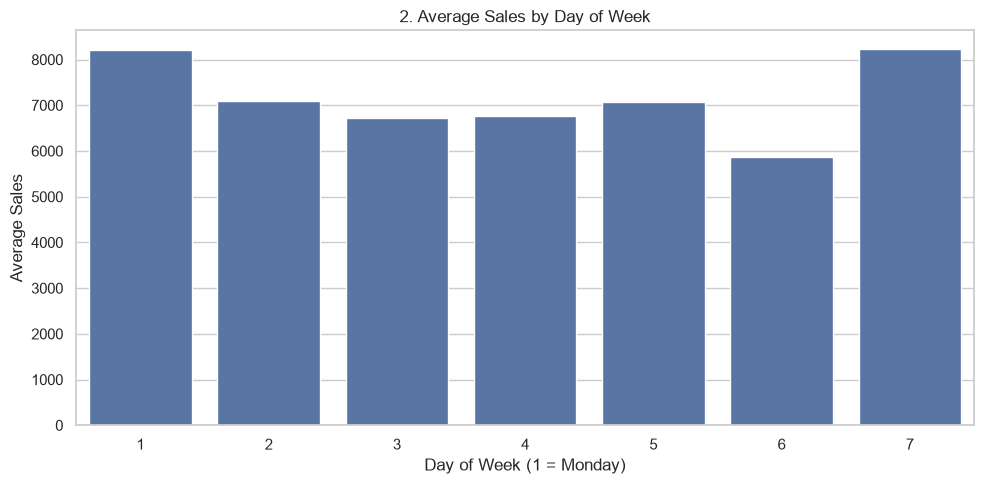

In [65]:
# Calculate average sales by day of week for open stores,
# including observations with zero sales

weekday_sales = (
    df.loc[df["Open"] == 1]
      .groupby("DayOfWeek")["Sales"]
      .mean()
      .reindex(range(1, 8))
)

plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_sales.index, y=weekday_sales.values)

plt.title("2. Average Sales by Day of Week")
plt.xlabel("Day of Week (1 = Monday)")
plt.ylabel("Average Sales")
plt.tight_layout()
plt.show()

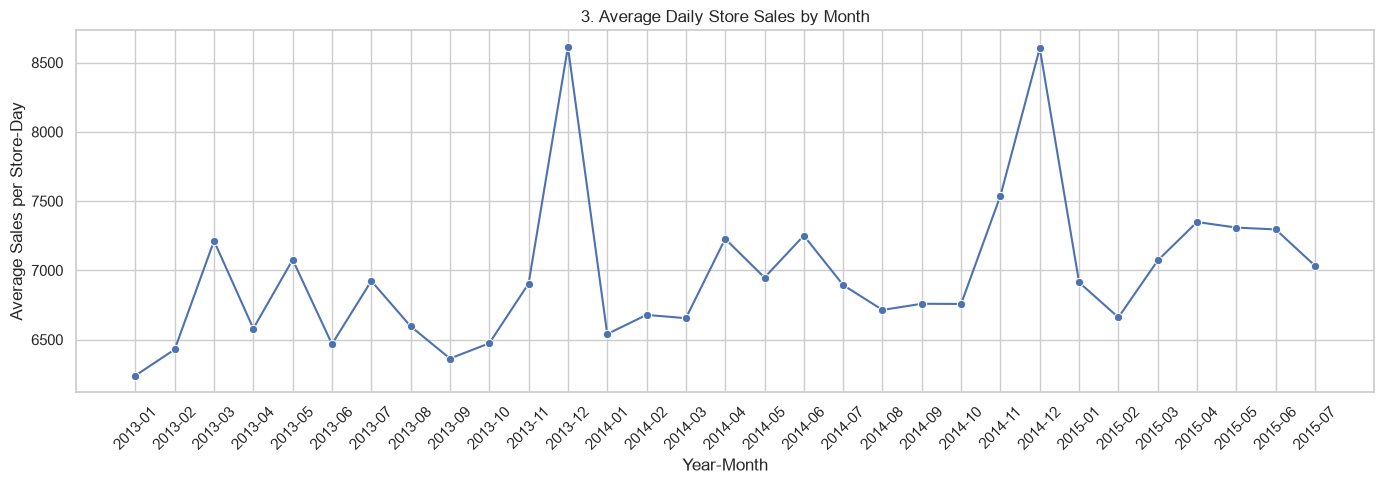

In [41]:
monthly_sales = (
    sales_df.groupby("YearMonth")["Sales"]
            .mean()
)

plt.figure(figsize=(14, 5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o")

plt.title("3. Average Daily Store Sales by Month")
plt.xlabel("Year-Month")
plt.ylabel("Average Sales per Store-Day")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

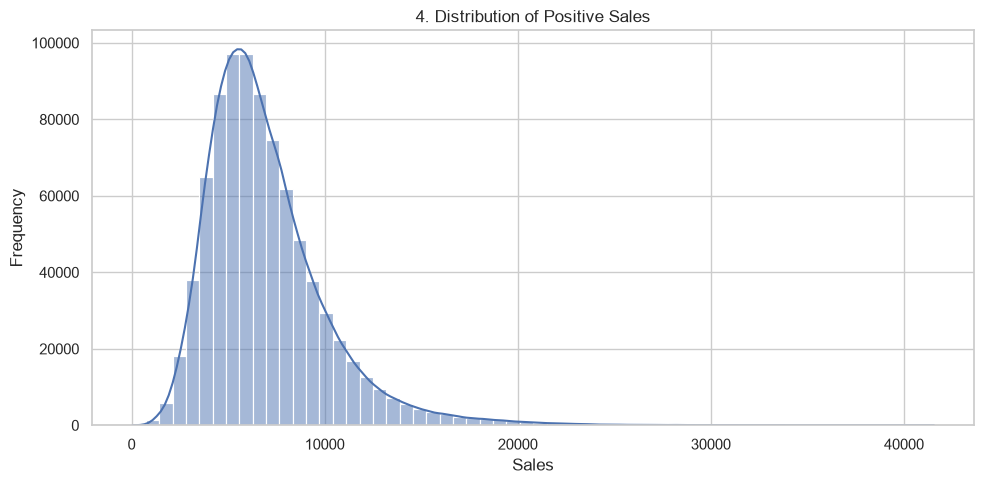

In [42]:
plt.figure(figsize=(10, 5))
sns.histplot(sales_df["Sales"], bins=60, kde=True)

plt.title("4. Distribution of Positive Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Wnioski:**

Rozkład dodatnich wartości sprzedaży charakteryzuje się wyraźną asymetrią prawostronną. Większość obserwacji koncentruje się w przedziale około 3 000–10 000, natomiast wysokie wartości sprzedaży występują znacznie rzadziej. Rozkład nie jest zbliżony do rozkładu normalnego i posiada długi prawy ogon. Wysokie wartości nie powinny być automatycznie traktowane jako błędy, ponieważ mogą odzwierciedlać rzeczywiste wzrosty sprzedaży. W dalszej analizie warto sprawdzić ich przyczyny oraz ocenić modele prognostyczne za pomocą walidacji czasowej.

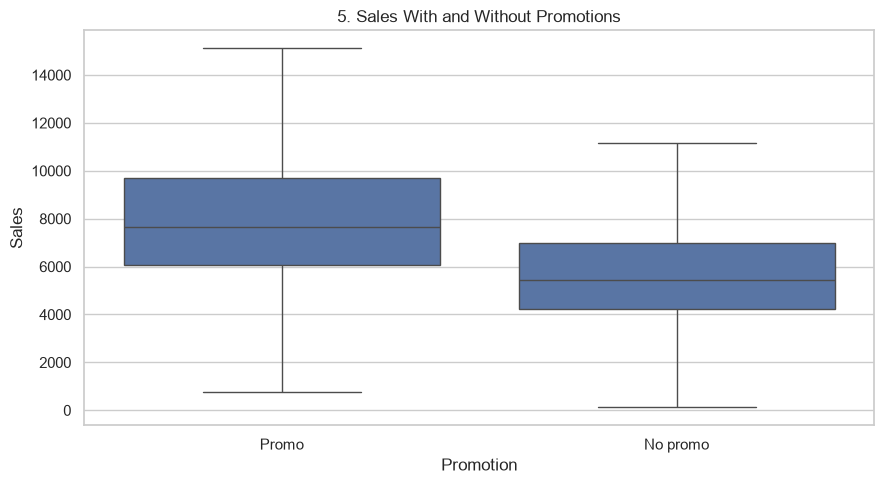

In [43]:
promo_sales = sales_df.copy()
promo_sales["PromoLabel"] = promo_sales["Promo"].map({
    0: "No promo",
    1: "Promo"
})

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=promo_sales,
    x="PromoLabel",
    y="Sales",
    showfliers=False
)

plt.title("5. Sales With and Without Promotions")
plt.xlabel("Promotion")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

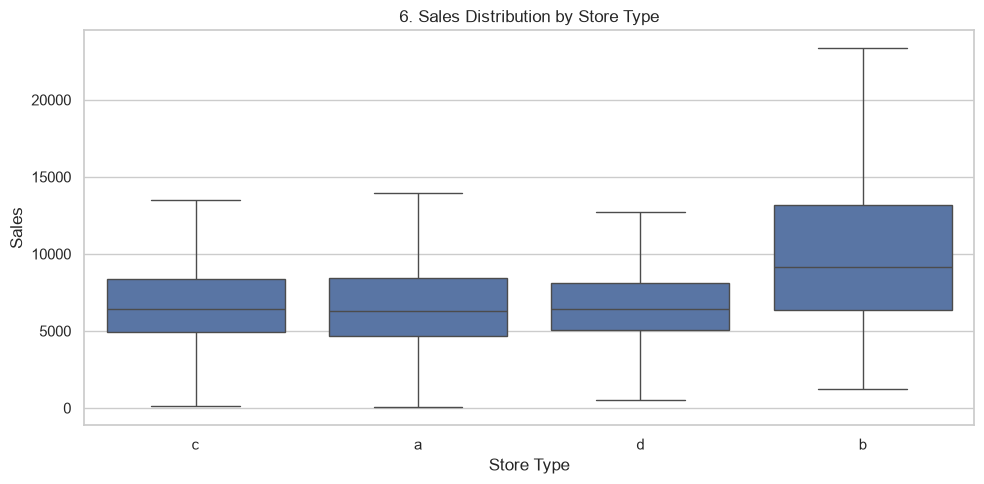

In [45]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=sales_df,
    x="StoreType",
    y="Sales",
    showfliers=False
)

plt.title("6. Sales Distribution by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

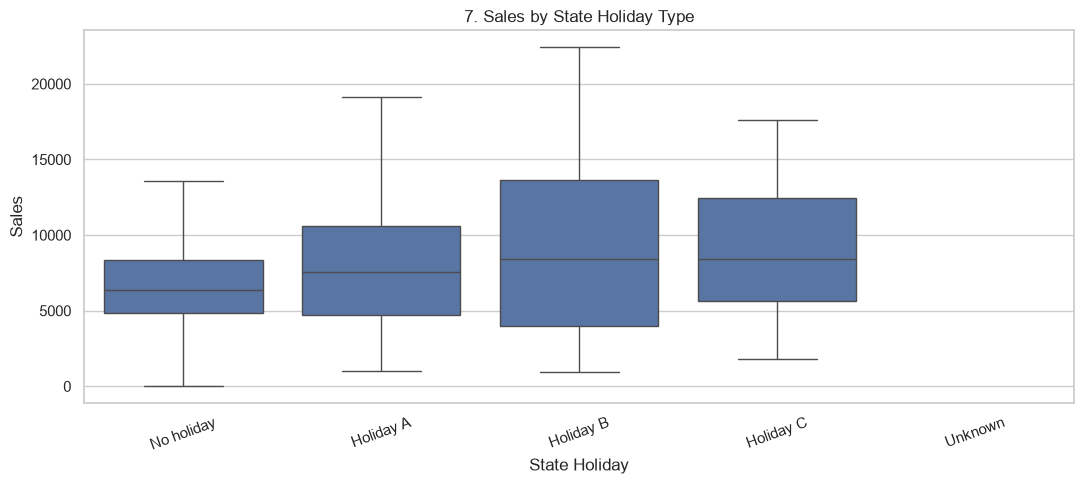

In [46]:
holiday_sales = sales_df.copy()

holiday_sales["StateHolidayLabel"] = (
    holiday_sales["StateHoliday"]
    .fillna("Unknown")
    .astype(str)
    .replace({
        "0": "No holiday",
        "a": "Holiday A",
        "b": "Holiday B",
        "c": "Holiday C"
    })
)

holiday_order = [
    "No holiday", "Holiday A", "Holiday B", "Holiday C", "Unknown"
]

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=holiday_sales,
    x="StateHolidayLabel",
    y="Sales",
    order=holiday_order,
    showfliers=False
)

plt.title("7. Sales by State Holiday Type")
plt.xlabel("State Holiday")
plt.ylabel("Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

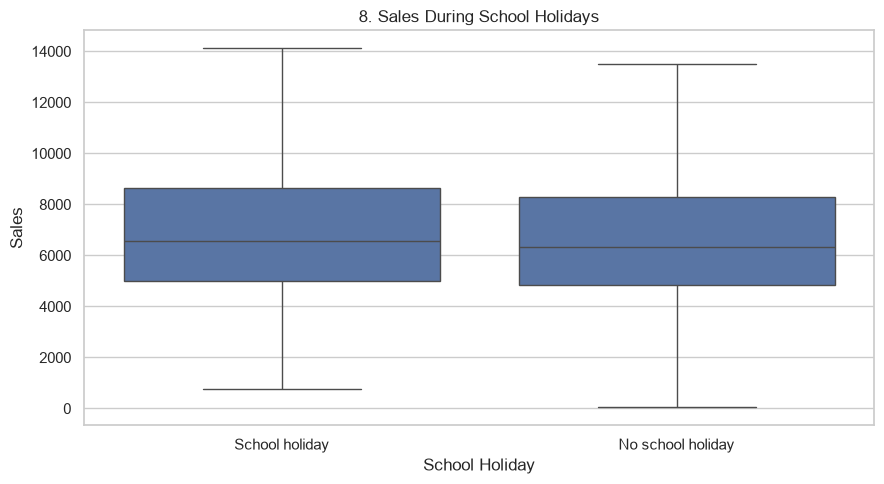

In [47]:
school_sales = sales_df.copy()

school_sales["SchoolHolidayLabel"] = (
    school_sales["SchoolHoliday"]
    .map({0: "No school holiday", 1: "School holiday"})
)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=school_sales,
    x="SchoolHolidayLabel",
    y="Sales",
    showfliers=False
)

plt.title("8. Sales During School Holidays")
plt.xlabel("School Holiday")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()


**Wnioski:**

Mediana sprzedaży w okresie wakacji szkolnych jest nieznacznie wyższa niż w dniach, w których nie występują wakacje szkolne. Rozkłady sprzedaży w obu grupach są jednak zbliżone, a ich zakresy międzykwartylowe w dużym stopniu się pokrywają. Wskazuje to, że sam fakt występowania wakacji szkolnych nie wiąże się z wyraźną różnicą w poziomie sprzedaży w analizowanych danych. Wpływ tego czynnika wymaga dalszej analizy z uwzględnieniem m.in. promocji, dnia tygodnia i typu sklepu.

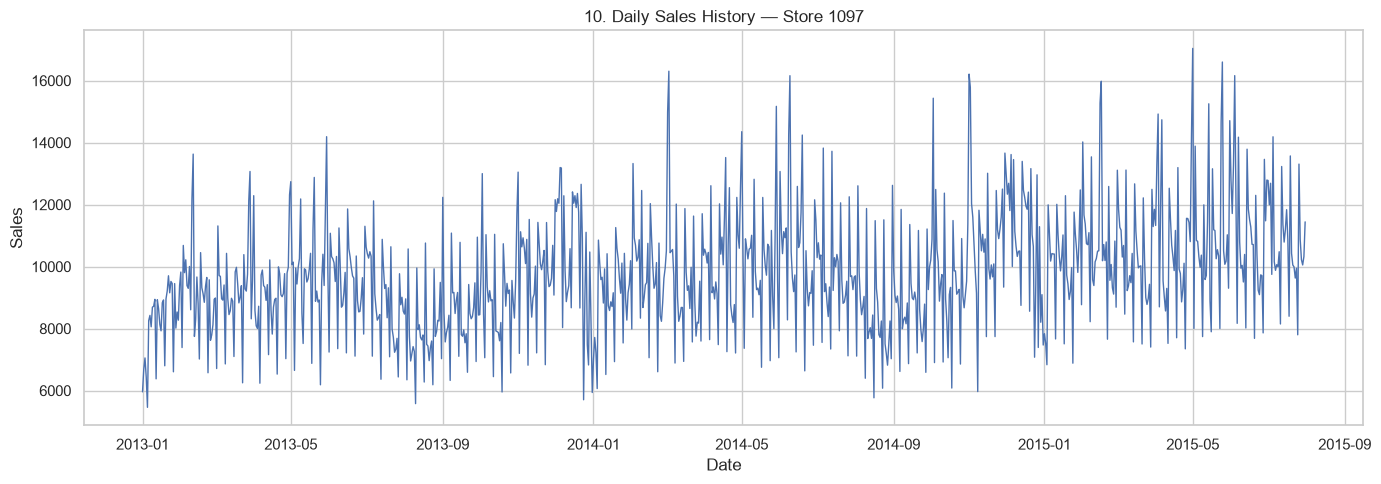

Selected store: 1097
Observations: 942


In [70]:
store_counts = (
    sales_df.groupby("Store")
            .size()
            .sort_values(ascending=False)
)

selected_store = int(store_counts.index[0])

store_history = (
    df.loc[df["Store"] == selected_store]
      .sort_values("Date")
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=store_history,
    x="Date",
    y="Sales",
    linewidth=1
)

plt.title(f"10. Daily Sales History — Store {selected_store}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

print("Selected store:", selected_store)
print("Observations:", len(store_history))

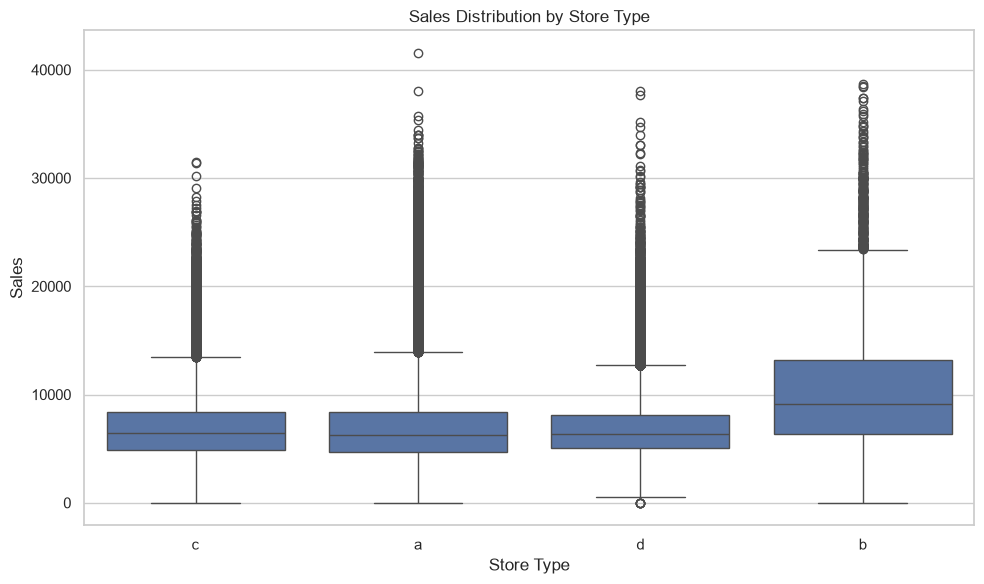

In [68]:
# Porównanie rozkładu sprzedaży według typu sklepu

open_df = df.loc[df["Open"] == 1].copy()

plt.figure(figsize=(10, 6))
sns.boxplot(data=open_df, x="StoreType", y="Sales")
plt.title("Sales Distribution by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

**Wnioski:**

Wykres pokazuje, że sklepy typu B charakteryzują się najwyższą medianą dziennej sprzedaży oraz większym zróżnicowaniem wyników niż pozostałe typy sklepów. Rozkłady sprzedaży w sklepach typu A, C i D są do siebie bardziej zbliżone. We wszystkich typach występuje wiele obserwacji odstających po stronie wysokich wartości sprzedaży, co wskazuje na występowanie dni o wyjątkowo wysokich obrotach. Wyniki sugerują, że typ sklepu może być istotną cechą w modelu prognostycznym, jednak warto również uwzględnić indywidualne cechy sklepów, promocje i sezonowość.

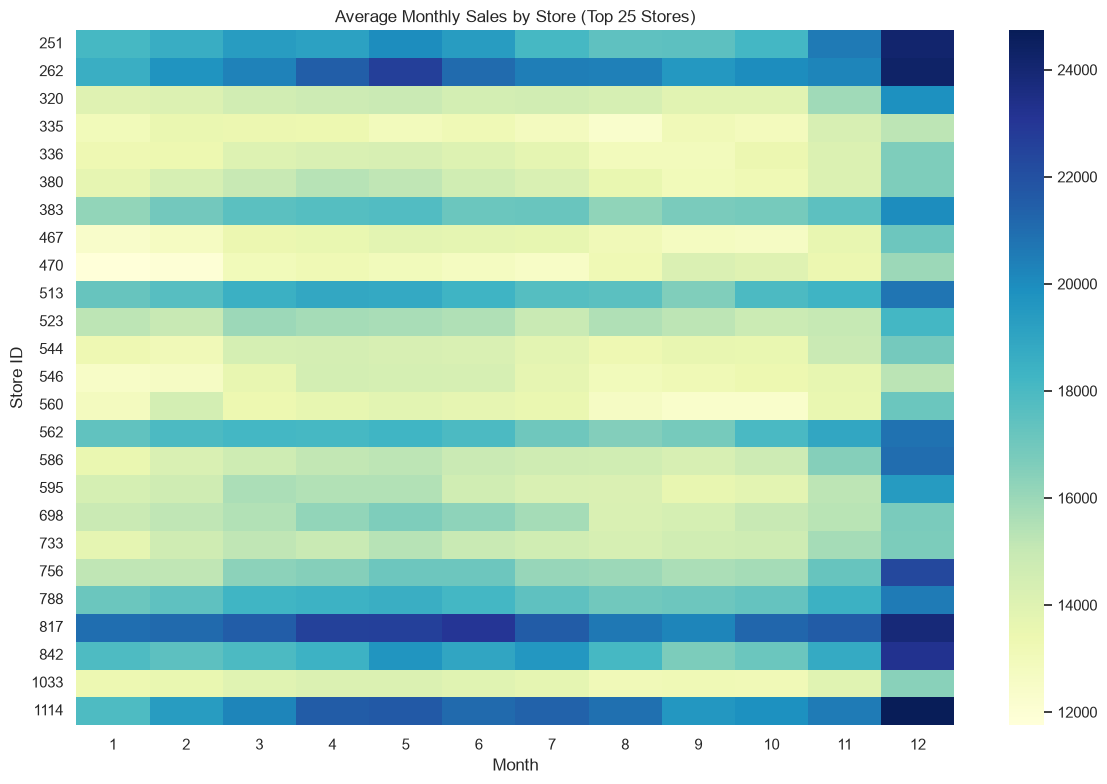

In [69]:
# Mapa cieplna średniej sprzedaży według sklepu i miesiąca

open_df = df.loc[df["Open"] == 1].copy()
open_df["Month"] = open_df["Date"].dt.month

top_stores = (
    open_df.groupby("Store")["Sales"]
           .mean()
           .nlargest(25)
           .index
)

heatmap_data = (
    open_df[open_df["Store"].isin(top_stores)]
    .pivot_table(
        index="Store",
        columns="Month",
        values="Sales",
        aggfunc="mean"
    )
)

plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu")
plt.title("Average Monthly Sales by Store (Top 25 Stores)")
plt.xlabel("Month")
plt.ylabel("Store ID")
plt.tight_layout()
plt.show()

**Wnioski:**

Mapa cieplna pokazuje wyraźne różnice w poziomie średniej miesięcznej sprzedaży pomiędzy poszczególnymi sklepami. Sklepy takie jak 817, 262, 251, 513 i 1114 osiągają relatywnie wysokie wartości w wielu miesiącach, natomiast w przypadku sklepów 335, 336, 380, 467 i 470 sprzedaż jest wyraźnie niższa. W grudniu w większości analizowanych sklepów widoczny jest wzrost średniej sprzedaży, co może wskazywać na występowanie sezonowości. Jednocześnie dynamika sprzedaży różni się pomiędzy sklepami, dlatego w modelowaniu warto uwzględnić zarówno cechy kalendarzowe, jak i indywidualne cechy poszczególnych sklepów.

In [72]:
summary = {
    "n_train_rows": len(train),
    "n_store_rows": len(stores),
    "n_stores_train": train["Store"].nunique(),
    "date_min": str(train["Date"].min().date()),
    "date_max": str(train["Date"].max().date()),
    "missing_train_cells": int(train.isna().sum().sum()),
    "missing_store_cells": int(stores.isna().sum().sum()),
    "duplicate_train_rows": int(train.duplicated().sum()),
    "duplicate_store_rows": int(stores.duplicated().sum()),
    "duplicate_store_date": int(
        train.duplicated(["Store", "Date"]).sum()
    ),
    "zero_sales_rows": int((train["Sales"] == 0).sum()),
    "negative_sales_rows": int((train["Sales"] < 0).sum()),
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
)

display(summary_df)

Path("../reports").mkdir(parents=True, exist_ok=True)

summary_df.to_csv(
    "../reports/data_quality_summary.csv",
    index=False
)

print("Data quality summary saved.")

,Metric,Value
0,n_train_rows,1017209
1,n_store_rows,1115
2,n_stores_train,1115
3,date_min,2013-01-01
4,date_max,2015-07-31
5,missing_train_cells,0
6,missing_store_cells,2343
7,duplicate_train_rows,0
8,duplicate_store_rows,0
9,duplicate_store_date,0


Data quality summary saved.


### Wnioski z analizy rozkładu sprzedaży i wybranych czynników

Rozkład dodatniej sprzedaży charakteryzuje się prawostronną asymetrią, co oznacza, że większość obserwacji skupia się w niższym i średnim zakresie wartości, natomiast pojedyncze obserwacje osiągają bardzo wysokie wartości. Sprzedaż w dniach objętych promocją jest wizualnie wyższa niż w dniach bez promocji, co wskazuje, że zmienna `Promo` może być istotnym predyktorem modelu.

Widoczne są również różnice między typami sklepów. Sklepy typu `b` charakteryzują się najwyższą medianą sprzedaży oraz największym zróżnicowaniem wyników. Rozkłady sprzedaży różnią się także w zależności od rodzaju święta państwowego, natomiast różnice między dniami z wakacjami szkolnymi i bez nich są stosunkowo niewielkie.

Na podstawie wykresów można uznać zmienne `Promo`, `StoreType` i `StateHoliday` za potencjalnie użyteczne cechy modelu. Zmienna `SchoolHoliday` również może dostarczać dodatkowych informacji. Zaobserwowane zależności mają charakter opisowy i nie dowodzą związku przyczynowo-skutkowego. Ich znaczenie należy zweryfikować podczas modelowania z uwzględnieniem sezonowości, dnia tygodnia i charakterystyki sklepu.

## Uzasadnienie zadania prognostycznego
Celem projektu jest opracowanie modelu prognozującego dzienną sprzedaż (Sales) dla pojedynczego sklepu sieci Rossmann w horyzoncie 30 dni.

Główną zmienną docelową jest Sales, czyli wartość sprzedaży danego sklepu w konkretnym dniu. Prognoza będzie generowana osobno dla każdego dnia okresu prognostycznego, z uwzględnieniem historycznych danych sprzedażowych, cech kalendarzowych oraz innych dostępnych informacji, które mogą wpływać na poziom sprzedaży.

Prognozowanie będzie dotyczyć dni, w których sklep jest otwarty. Dni zamknięcia zostaną obsłużone oddzielnie: dla dni, w których sklep jest zamknięty, sprzedaż będzie przyjmowana jako zero, a obserwacje te nie będą uwzględniane przy ocenie dokładności prognoz sprzedaży w dniach otwarcia.
